# Week 5 · Class 1 — Probability & Distributions in Python 🎲⌚

**90 min · hands-on** · tools: `numpy`, `pandas`, `matplotlib`, `scipy.stats`

This notebook is the practical side of today's slides. The big idea: **if you can simulate it, you can understand it.**
Every formula from the lecture gets checked twice: once with a **simulation** and once on **real-looking wearable data** (the `wearables_daily.csv` file from Week 3).

| Part | Time | What we do |
|---|---|---|
| 0 | 3' | Setup |
| 1 | 12' | Probability = long-run frequency (simulating dice) |
| 2 | 8' | Probabilities from data: events are boolean masks |
| 3 | 12' | Conditional probability: does short sleep raise stress? |
| 4 | 12' | Bayes: the smartwatch AFib alert |
| 5 | 12' | Expected value and variance |
| 6 | 10' | Why the sample variance divides by n − 1 |
| 7 | 15' | Distributions with `scipy.stats` |
| 8 | 6' | Final challenge + recap |

🧑‍💻 = we write it **together** · ✋ **Your turn** = 2–3 minutes on your own, then we compare.

### 📂 Dataset used in this notebook
| | |
|---|---|
| **File** | `wearables_daily.csv` (the same file as in Week 3, Class 2) |
| **Size** | 250 users × 365 days = **91,250 rows**, 17 columns |
| **Columns we use** | `steps`, `sleep_hours`, `resting_hr`, `stress_score`, `device`, `date` |
| **Used in** | Parts 2, 3, 4 (last exercise), 6 and 7 |
| **Not needed in** | Parts 1, 4 (AFib), 5 and 8: there we **simulate** random numbers with numpy |

Each row is **one user-day** from a wearable device: daily steps, sleep, resting heart rate and a stress score.

## 0 · Setup ⚙️

📁 **Before running:** put `wearables_daily.csv` next to this notebook.
- **Colab:** click the folder icon on the left and drag the file in (it is deleted when the session ends, so upload it again next time).
- **VS Code / Jupyter:** keep it in the same folder as the notebook, or change the path in `pd.read_csv(...)` below.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

rng = np.random.default_rng(42)    # our random number generator; 42 = seed → same results every run

In [3]:
df = pd.read_csv("../data/wearables_daily.csv", parse_dates=["date"])
print(df.shape)
df[["user_id", "date", "steps", "sleep_hours", "resting_hr", "stress_score"]].head()

(91250, 17)


,user_id,date,steps,sleep_hours,resting_hr,stress_score
0,U001,2025-10-01,11208,6.24,68.0,56.0
1,U001,2025-10-02,14360,5.86,65.0,56.0
2,U001,2025-10-03,10323,6.95,65.0,56.0
3,U001,2025-10-04,10048,7.06,65.0,41.0
4,U001,2025-10-05,10675,6.76,64.0,59.0


> 💡 **Why a seed?** Random numbers in a computer are generated by an algorithm. Fixing the *seed* means everyone in the room gets exactly the same "random" numbers, so we can compare results.

---
## 1 · Probability = long-run frequency 🎲 (12')

Slides: *P(A) ≈ the fraction of times A happens if we repeat the experiment many times.*
Let's roll a die **10 times**, then **100,000 times**.

In [9]:
# ✍️ live coding
lls = rng.integers(1,7, size=10)
print(lls)

[1 5 5 3 1 6 3 6 5 5]


In [13]:
# ✍️ live coding
lls = rng.integers(1,7, size=10000)
is_even = lls % 2 == 0

print("first elements of the list", lls[:10]) 
print("is even", is_even[:10])
print("P(even)=", is_even.mean())


first elements of the list [3 5 3 2 5 3 2 4 2 4]
is even [False False False  True False False  True  True  True  True]
P(even)= 0.5022


⭐ **Trick to remember:** the mean of a boolean array is the **fraction of `True`**. We will use this all day: `mask.mean()` = estimated probability.

Now let's **watch** the frequency settle down as we roll more and more.

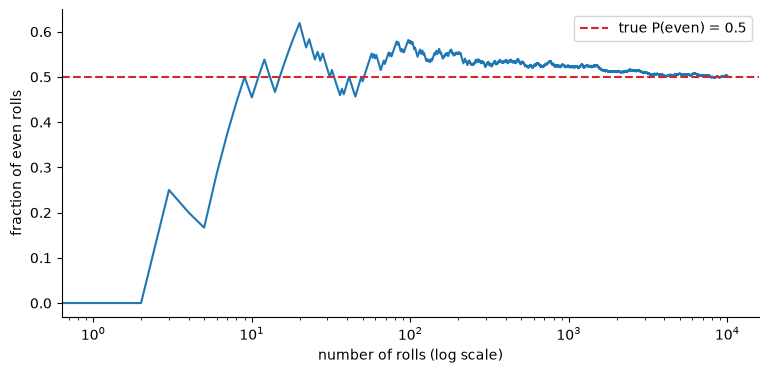

In [14]:
# ✍️ live coding
running_freq = np.cumsum(is_even) / np.arange(1, len(is_even) + 1)


plt.plot(running_freq, color="tab:blue")
plt.axhline(0.5, color="tab:red", ls="--", label="true P(even) = 0.5")
plt.xscale("log")
plt.xlabel("number of rolls (log scale)"); plt.ylabel("fraction of even rolls")
plt.legend(); plt.show()

With few rolls the frequency jumps around; with many rolls it gets close to 0.5. This is the **law of large numbers**.

### Two dice: exact answer vs simulation
Sample space Ω = all 36 pairs (die 1, die 2). All equally likely → **P(A) = favourable / possible**.

In [15]:
# ✍️ live coding
## sample space omega 
omega = [(a,b) for a in range(1,7) for b in range(1,6)]
## define a favourable outcome as an event where the sum of the outcomes is 7

favourable = [(a,b) for (a,b) in omega if a+b ==7]
print("favourable outcomes:", favourable )

favourable outcomes: [(2, 5), (3, 4), (4, 3), (5, 2), (6, 1)]


🧑‍💻 **Code with me:** estimate P(sum = 7) by simulating 100,000 throws of two dice.

In [35]:
# ✍️ live coding
## 1000 000 simulations rolling a die random generator in the same way
sample_size = 10000000
die_1 = rng.integers(1,7, size= sample_size )
die_2 = rng.integers(1,7, size= sample_size )

total = die_1 + die_2 

## P(sum ==7) = sum(die_1 + die_2 == 7).mean()

print(total ==7)
print("simulated P(sum ==7) =", (total ==7).mean() )
print(total)

[False False False ...  True False False]
simulated P(sum ==7) = 0.1666241
[ 6  5  6 ...  7  3 11]


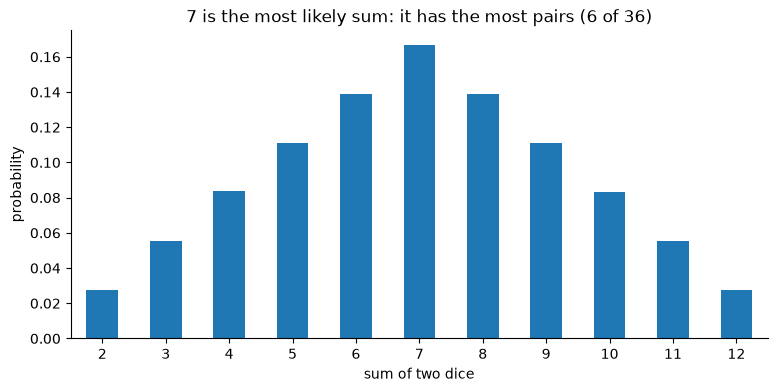

In [36]:
# ✍️ live coding
# The whole distribution of the sum: 2 ... 12
freq = pd.Series(total).value_counts(normalize=True).sort_index()   # normalize=True → fractions instead of counts
freq.plot(kind="bar", color="tab:blue")
plt.xlabel("sum of two dice"); plt.ylabel("probability"); plt.xticks(rotation=0)
plt.title("7 is the most likely sum: it has the most pairs (6 of 36)"); plt.show()

### Check the rules from the slides
- **Complement:** P(not A) = 1 − P(A)
- **Union:** P(A or B) = P(A) + P(B) − P(A and B)

With numpy masks: **or** = `|`, **and** = `&`, **not** = `~` (always use brackets around each condition!).

In [ ]:
# ✍️ live coding


✋ **Your turn (2'):** estimate the probability that **at least one** of the two dice shows a 6.
*Hint:* use `|`. Then check with the complement: 1 − P(no 6 at all) = 1 − (5/6)².

In [ ]:
# ✍️ live coding


---
## 2 · Probabilities from data: events are boolean masks ⌚ (8')

In real life we don't know the true probabilities: we **estimate** them from data, exactly like with the dice.
Each row of our dataset is one **user-day**. An *event* is a condition on a row, e.g. "the user walked at least 10,000 steps".

First, a tiny bit of cleaning (we found these issues in Week 3): sensor glitches in `steps` and missing sleep values.

In [38]:
df

,user_id,date,city,device,age,gender,steps,active_minutes,sleep_hours,deep_sleep_pct,resting_hr,hrv_ms,stress_score,calories,age_group,lat,lon
0,U001,2025-10-01,Berlin,Apple Watch,58,female,11208,91.0,6.24,12.8,68.0,38.7,56.0,2412.0,50-59,52.52,13.4
1,U001,2025-10-02,Berlin,Apple Watch,58,female,14360,123.0,5.86,17.7,65.0,38.6,56.0,2666.0,50-59,52.52,13.4
2,U001,2025-10-03,Berlin,Apple Watch,58,female,10323,81.0,6.95,15.6,65.0,31.5,56.0,2337.0,50-59,52.52,13.4
3,U001,2025-10-04,Berlin,Apple Watch,58,female,10048,87.0,7.06,24.8,65.0,30.5,41.0,2350.0,50-59,52.52,13.4
4,U001,2025-10-05,Berlin,Apple Watch,58,female,10675,98.0,6.76,12.8,64.0,39.0,59.0,2419.0,50-59,52.52,13.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91245,U250,2026-09-26,Amsterdam,Withings,59,male,10582,85.0,7.07,15.1,67.0,31.5,57.0,2363.0,50-59,52.37,4.9
91246,U250,2026-09-27,Amsterdam,Withings,59,male,7547,72.0,8.01,10.1,65.0,NaN,39.0,2190.0,50-59,52.37,4.9
91247,U250,2026-09-28,Amsterdam,Withings,59,male,21252,184.0,7.22,15.9,70.0,34.1,49.0,3186.0,50-59,52.37,4.9
91248,U250,2026-09-29,Amsterdam,Withings,59,male,20826,173.0,7.52,27.3,63.0,NaN,35.0,3125.0,50-59,52.37,4.9


In [39]:
# ✍️ live coding
data = df[df["steps"] < 60000].dropna(subset=["sleep_hours"]).copy()
print(f"kepty {len(data):,} of {len(df):,} rows")

kepty 88,456 of 91,250 rows


In [40]:
# ✍️ live coding
data

,user_id,date,city,device,age,gender,steps,active_minutes,sleep_hours,deep_sleep_pct,resting_hr,hrv_ms,stress_score,calories,age_group,lat,lon
0,U001,2025-10-01,Berlin,Apple Watch,58,female,11208,91.0,6.24,12.8,68.0,38.7,56.0,2412.0,50-59,52.52,13.4
1,U001,2025-10-02,Berlin,Apple Watch,58,female,14360,123.0,5.86,17.7,65.0,38.6,56.0,2666.0,50-59,52.52,13.4
2,U001,2025-10-03,Berlin,Apple Watch,58,female,10323,81.0,6.95,15.6,65.0,31.5,56.0,2337.0,50-59,52.52,13.4
3,U001,2025-10-04,Berlin,Apple Watch,58,female,10048,87.0,7.06,24.8,65.0,30.5,41.0,2350.0,50-59,52.52,13.4
4,U001,2025-10-05,Berlin,Apple Watch,58,female,10675,98.0,6.76,12.8,64.0,39.0,59.0,2419.0,50-59,52.52,13.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91245,U250,2026-09-26,Amsterdam,Withings,59,male,10582,85.0,7.07,15.1,67.0,31.5,57.0,2363.0,50-59,52.37,4.9
91246,U250,2026-09-27,Amsterdam,Withings,59,male,7547,72.0,8.01,10.1,65.0,NaN,39.0,2190.0,50-59,52.37,4.9
91247,U250,2026-09-28,Amsterdam,Withings,59,male,21252,184.0,7.22,15.9,70.0,34.1,49.0,3186.0,50-59,52.37,4.9
91248,U250,2026-09-29,Amsterdam,Withings,59,male,20826,173.0,7.52,27.3,63.0,NaN,35.0,3125.0,50-59,52.37,4.9


🧑‍💻 **Code with me:** P(short sleep **and** high stress) and P(short sleep **or** high stress). Check the union rule on real data.

In [41]:
# ✍️ live coding
population = data["resting_hr"].to_numpy()

sigma2 = population.var(ddof=0)
print("true population variance", sigma2) ## population variance

true population variance 27.436072993103256


In [42]:
n = 5 ## size of the sample

samples = rng.choice(population, size =(20_000, n))

var_n = samples.var(axis=1, ddof=0) ## divide by n
var_n1 = samples.var(axis=1, ddof=1) ## divide by n-1


print(f"average of ÷n      : {var_n.mean():.2f}")
print(f"average of ÷(n − 1): {var_n1.mean():.2f}")
print(f"true σ²            : {sigma2:.2f}")
print(f"theory: ÷n gives (n−1)/n · σ² = {(n - 1) / n * sigma2:.2f}")

average of ÷n      : 21.92
average of ÷(n − 1): 27.40
true σ²            : 27.44
theory: ÷n gives (n−1)/n · σ² = 21.95


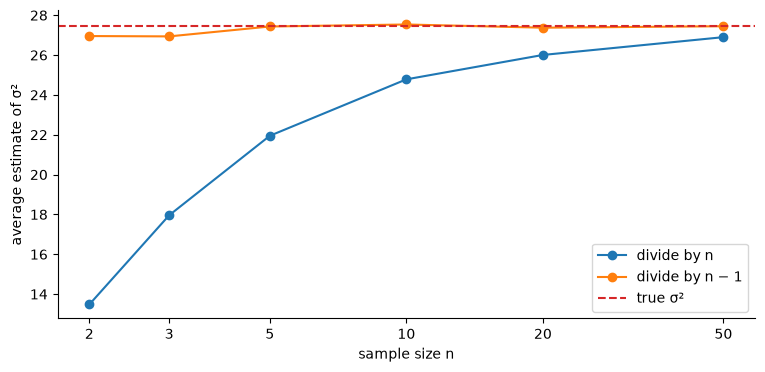

In [43]:
sizes = [2, 3, 5, 10, 20, 50]
avg_n, avg_n1 = [], []
for n in sizes:
    s = rng.choice(population, size=(20_000, n))
    avg_n.append(s.var(axis=1, ddof=0).mean())
    avg_n1.append(s.var(axis=1, ddof=1).mean())

plt.plot(sizes, avg_n, "o-", label="divide by n")
plt.plot(sizes, avg_n1, "o-", label="divide by n − 1")
plt.axhline(sigma2, color="tab:red", ls="--", label="true σ²")
plt.xscale("log"); plt.minorticks_off(); plt.xticks(sizes, sizes)
plt.xlabel("sample size n"); plt.ylabel("average estimate of σ²"); plt.legend(); plt.show()

In [ ]:
X = stats.binom(n=20, p=p_goal)
k = np.arange(0, 21)

# real data: for each date, pick 20 random users and count how many hit the goal
real_counts = (data.groupby("date")["goal"]
                   .apply(lambda g: g.sample(20, random_state=0).sum()))

plt.hist(real_counts, bins=np.arange(-0.5, 21), density=True, alpha=0.5, label="real days (20 random users)")
plt.plot(k, X.pmf(k), "o-", color="tab:red", label="Binomial(20, p) theory")
plt.xlabel("users hitting the goal (out of 20)"); plt.ylabel("probability"); plt.legend(); plt.show()

print(f"theory: E[X] = {X.mean():.2f}, σ = {X.std():.2f}  |  data: mean = {real_counts.mean():.2f}, std = {real_counts.std():.2f}")

---
## 3 · Conditional probability: does short sleep raise stress? 😴➡️😰 (12')

$$P(A \mid B) = \frac{P(A \cap B)}{P(B)}$$

In words: **keep only the rows where B happened**, then compute how often A happens there.

In [ ]:
# ✍️ live coding


In [ ]:
# ✍️ live coding


### Way 3: `pd.crosstab` — the table from the slides in one line
`normalize="index"` divides every row by its total → each row becomes a **conditional** distribution.

In [ ]:
# ✍️ live coding


In [ ]:
# ✍️ live coding


📌 **Reading:** after a short night, the chance of a high-stress day is about **3 times** higher than after a normal night.

**Independence check:** A and B are independent if P(A | B) = P(A). Here 0.56 ≠ 0.22 → sleep and stress are **dependent**.

> ⚠️ Dependent ≠ causal. Maybe stressed people sleep badly, or a third factor (a deadline!) causes both. Probability only tells us they move together.

✋ **Your turn (3'):**
1. Compute P(hit step goal | device) for every device. Hint: `data.groupby("device")` and the mean of a boolean column.
2. Is hitting the goal independent of the device?

In [ ]:
# ✍️ live coding


*Answer:* if goal and device were independent, every device would give the overall P(goal) ≈ 0.26. Garmin users hit it about 27% of the time and Apple Watch users about 24%: a small gap, but with 20,000+ days per device it is probably not just noise. Thursday we learn how to **test** that properly.

---
## 4 · Bayes: the smartwatch AFib alert ❤️⌚ (12')

$$P(A \mid B) = \frac{P(B \mid A)\,P(A)}{P(B)}, \qquad P(B) = P(B\mid A)P(A) + P(B \mid A^c)P(A^c)$$

From the slides: 2% of users over 65 have AFib, the watch detects it 95% of the time, and gives a false alarm to 5% of healthy users.

🧑‍💻 **Code with me:** a function we can reuse for any test.

In [ ]:
# ✍️ live coding


Don't trust the formula? **Simulate 100,000 users** and count, exactly like the tree on the slide.

In [ ]:
# ✍️ live coding


### The prior matters: how does P(AF | alert) change with how common AF is?

In [ ]:
# ✍️ live coding


### Updating twice
After one alert, your belief went from 2% to 28%. That **posterior becomes the new prior**. What if a second, independent check also alerts?

In [ ]:
# ✍️ live coding


✋ **Your turn (3'):** use Bayes on our wearable data. Compute **P(short sleep | high stress)** in two ways:
1. directly by filtering the rows,
2. with Bayes from P(high stress | short sleep), P(short sleep) and P(high stress).

In [ ]:
# ✍️ live coding


---
## 5 · Expected value and variance 🎯 (12')

For a random variable X with values x and probabilities P(X = x):

$$\mathrm{E}[X] = \mu = \sum_x x\,P(X=x) \qquad \mathrm{Var}(X) = \sum_x (x-\mu)^2\,P(X=x) \qquad \sigma = \sqrt{\mathrm{Var}(X)}$$

In [ ]:
# ✍️ live coding


In [ ]:
# ✍️ live coding


### Is the game worth it?
You pay 2 €, roll a die, and win 6 € only if you roll a 6. The expected value tells us what happens **on average over many games**.

In [ ]:
# ✍️ live coding


🧑‍💻 **Code with me:** a **loaded die** that shows 6 half of the time and every other face with probability 0.1. Compute E[X] and Var(X). Is it riskier than a fair die?

In [ ]:
# ✍️ live coding


### Shortcut you will see in books
$$\mathrm{Var}(X) = \mathrm{E}[X^2] - \mu^2$$

In [ ]:
# ✍️ live coding


---
## 6 · Why the sample variance divides by n − 1 🔍 (10')

Let's play God: we treat **all 88,000 resting heart rates** in our data as the **population**. We know the true variance σ².
Then we pretend to be a researcher who only sees a **small sample of n = 5** and estimates σ² from it. We repeat that 20,000 times.

In [ ]:
# ✍️ live coding


In [ ]:
# ✍️ live coding


🧑‍💻 **Code with me:** repeat for several sample sizes and plot. The bias of ÷n disappears only when n is large.

In [ ]:
# ✍️ live coding


### ⚠️ The trap: numpy and pandas have different defaults
| Tool | Default | Divides by |
|---|---|---|
| `np.var`, `np.std` | `ddof=0` | n |
| `pd.Series.var`, `.std`, `df.describe()` | `ddof=1` | n − 1 |

In [ ]:
# ✍️ live coding


✅ **Rule:** always write `ddof` explicitly. Data science almost always works with samples → `ddof=1`.

---
## 7 · Distributions with `scipy.stats` 📊 (15')

Every distribution in `scipy.stats` works the same way (it's a class, remember Week 2!):

| Method | Meaning |
|---|---|
| `.pmf(k)` / `.pdf(x)` | bar height (discrete) / density (continuous) |
| `.cdf(x)` | P(X ≤ x) |
| `.sf(x)` | P(X > x) = 1 − cdf |
| `.ppf(q)` | the value x with P(X ≤ x) = q (percentiles) |
| `.rvs(size)` | random samples |
| `.mean()`, `.var()`, `.std()` | theoretical mean, variance, std |

### 7.1 Bernoulli → Binomial: hitting the step goal
One user-day = one yes/no trial → **Bernoulli(p)**. We estimate p from the data.

In [ ]:
# ✍️ live coding


A team of **20 users**: how many hit the goal on a given day? If users are independent, X ~ **Binomial(n = 20, p)**.
Let's compare the theory with real days from our data.

In [ ]:
# ✍️ live coding


📌 **The model is close but not perfect:** the real counts are **more spread out** than the Binomial. Why? The Binomial assumes every user-day has the **same p** and users are **independent**. In reality, on a sunny Sunday *everybody* walks more and on a rainy Monday *everybody* walks less, so the counts on the same day move together. Checking assumptions is part of the job!

🧑‍💻 **Code with me:** P(exactly 5 hit the goal), P(at most 3), P(more than 8).

In [ ]:
# ✍️ live coding


### 7.2 Poisson: counts per interval
Suppose an app sends on average λ = 3 notifications per hour. Number per hour ~ **Poisson(3)**. Mean **and** variance are both λ.

In [ ]:
# ✍️ live coding


### 7.3 Normal: resting heart rate
Many biological measurements look like a bell. We **fit** a Normal by plugging in the sample mean and std, and compare with the histogram.

In [ ]:
# ✍️ live coding


🧑‍💻 **Code with me:** check the **68–95–99.7 rule** on the data, and compare to the Normal model.

In [ ]:
# ✍️ live coding


In [ ]:
# ✍️ live coding


📌 Close, but not perfect: the data has a longer **left** tail (very fit people with a low resting HR) and fewer very high values than the Normal predicts (3.7% vs 5.7% above 80 bpm). A model is a **useful approximation**: always check it against the data.

> 🧠 For a continuous variable, P(HR = exactly 72.000…) = 0. Probabilities are **areas**: `H.cdf(b) − H.cdf(a)`.

### 7.4 Exponential and Uniform (quick look)

In [ ]:
# ✍️ live coding


In [ ]:
# ✍️ live coding


---
## 8 · Final challenge 🏁 (6')

✋ **Your turn** (the exercise from the slides): a team of **20 users**, each hits the goal with probability **0.3**, independently. X = number who hit it.
1. Which distribution? Compute E[X], Var(X) and σ with `scipy.stats`.
2. P(X = 0)?
3. Check your answer to 2 with a simulation of 100,000 days.
4. Resting HR ~ Normal(62, 8): which share of users is above 78 bpm?

In [ ]:
# ✍️ live coding


## 🧭 Recap

| Idea | Python |
|---|---|
| probability ≈ long-run frequency | `mask.mean()` |
| and / or / not | `A & B`, `A \| B`, `~A` |
| conditional probability | `A[B].mean()` or `pd.crosstab(..., normalize="index")` |
| Bayes | `sens * prior / (sens * prior + fpr * (1 - prior))` |
| expected value, variance | `np.sum(x * p)`, `np.sum((x - mu)**2 * p)` |
| sample variance | `ddof=1` (pandas default), numpy default is `ddof=0` |
| distributions | `stats.binom`, `stats.poisson`, `stats.norm`, `stats.expon`, `stats.uniform` + `.pmf/.pdf/.cdf/.sf/.ppf/.rvs` |

🧪 **Saturday labs:** probability intro · discrete & continuous distributions.
🔜 **Thursday:** samples vs populations, the central limit theorem, confidence intervals and hypothesis tests. Today's simulations are exactly how we will *see* the CLT.